# Satellite positions from two-line element set

This notebook finds the positions of a satellite given its two-line element set (TLE) using `astropy` and `sgp4` (inspired by https://docs.astropy.org/en/stable/coordinates/satellites.html, with some extra info from https://rhodesmill.org/skyfield/earth-satellites.html).

In [2]:
import numpy as np
import sys, glob, os, time
from astropy import cosmology, units, constants
from astropy.time import Time
from astropy.timeseries import TimeSeries
from astropy.coordinates import TEME, CartesianDifferential, CartesianRepresentation, ITRS, EarthLocation, AltAz
import pyuvdata
from scipy import interpolate
from sgp4.api import Satrec, SGP4_ERRORS
from sgp4.earth_gravity import wgs72
from sgp4.io import twoline2rv
from tqdm import tqdm

In [3]:
import matplotlib.pyplot as plt
from matplotlib import colors, cm, colormaps, rc
rc("font", **{"family": "serif", "serif": ["times new roman"], "size": 15})
rc("text", usetex=True)
rc("axes", linewidth=1.5)

In [4]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [5]:
pyuvdata.__version__

'3.2.1'

## Satellite position

For satellite Starlink-31 (NORAD CAT ID 44235), from https://www.space-track.org/#catalog or https://celestrak.org/NORAD/elements/index.php for more recent TLE. See https://en.wikipedia.org/wiki/Two-line_element_set on how to read them.

In [6]:
s = '1 44235U 19029A   20275.31341942  .09808971  12623-4  18159-3 0  9999'
t = '2 44235  52.9736  36.3928 0009041 295.9879 160.3065 16.46847225 76971'

satellite = Satrec.twoline2rv(s, t)


Note: Satellite orbital elements go rapidly out of date. You will want to pay attention to the “epoch” date — the date on which a particular element set is most accurate. The element set might only be useful for a couple of weeks to either side of its epoch. For earlier dates, you will want to pull old elements from an archive; for later dates, you will want to download a fresh set of elements.

### Finding TEME Coordinates from TLE Data

We will use the `sgp4` python package to convert TLE into coordinates (https://pypi.org/project/sgp4/). Note the package can also handle OMM.

The `satellite` object has a method, `satellite.sgp4`, that will try to compute the TEME position and velocity at a given time (Julian date or now):

In [7]:
# t0 = Time.now() # 
t0 = Time(2458827.362605, format='jd')
# t0 = Time('2023-01-01T02:00:00')
print(t0.to_datetime())  # UTC

2019-12-09 20:42:09.071993


In [8]:
error_code, teme_p, teme_v = satellite.sgp4(t0.jd1, t0.jd2)  # in km and km/s
if error_code != 0:
    raise RuntimeError(SGP4_ERRORS[error_code])

Now that we have the position and velocity in kilometers and kilometers per second, we can create a position in the TEME reference frame (True Equator Mean Equinox frame):

In [9]:
teme_p = CartesianRepresentation(teme_p*units.km)
teme_v = CartesianDifferential(teme_v*units.km/units.s)
teme = TEME(teme_p.with_differentials(teme_v), obstime=t0)

Note how we are careful to set the observed time of the TEME frame to the time at which we calculated satellite position.

### Transforming TEME to Other Coordinate Systems

To find the overhead latitude, longitude, and height of the satellite

In [10]:
itrs_geo = teme.transform_to(ITRS(obstime=t0))
location = itrs_geo.earth_location
location.geodetic  

GeodeticLocation(lon=<Longitude -67.56687192 deg>, lat=<Latitude 28.46711715 deg>, height=<Quantity 27820.98661486 km>)

In [11]:
location.geodetic.height, location.geodetic.lat, location.geodetic.lon

(<Quantity 27820.98661486 km>,
 <Latitude 28.46711715 deg>,
 <Longitude -67.56687192 deg>)

Or, if you want to find the altitude and azimuth of the satellite from a particular location:

In [15]:
# siding_spring = EarthLocation.of_site('aao')  
# topo_itrs_repr = itrs_geo.cartesian.without_differentials() - siding_spring.get_itrs(t).cartesian
# itrs_topo = ITRS(topo_itrs_repr, obstime = t, location=siding_spring)
# aa = itrs_topo.transform_to(AltAz(obstime=t, location=siding_spring))

Look at the evolution of the satellite's altitude over a few months:

In [13]:
# t0 = Time(2458827.362605, format='jd')
t0 = Time('2019-05-24T02:00:00')  # launch date 
ts1 = TimeSeries(time_start=t0,
                 time_delta=1 * (units.sday),  # sideral day
                 n_samples=600)

dates = [t1.to_value('iso', subfmt='date') for t1 in ts1['time']]
heights = np.zeros(len(dates))
latitudes = np.zeros(len(dates))
longitudes = np.zeros(len(dates))
for u, t1 in enumerate(tqdm(ts1['time'])):
    error_code, teme_p, teme_v = satellite.sgp4(t1.jd1, t1.jd2)  # in km and km/s
    teme_p = CartesianRepresentation(teme_p*units.km)
    teme_v = CartesianDifferential(teme_v*units.km/units.s)
    teme = TEME(teme_p.with_differentials(teme_v), obstime=t1)
    itrs_geo = teme.transform_to(ITRS(obstime=t1))
    location = itrs_geo.earth_location  # km 
    if not np.isnan(location.geodetic.height.value):
        heights[u] = location.geodetic.height.value
        latitudes[u] = location.geodetic.lat.value  # deg
        longitudes[u] = location.geodetic.lon.value  # deg

100%|██████████| 600/600 [00:05<00:00, 119.72it/s]


Decay date is 2020/10/01


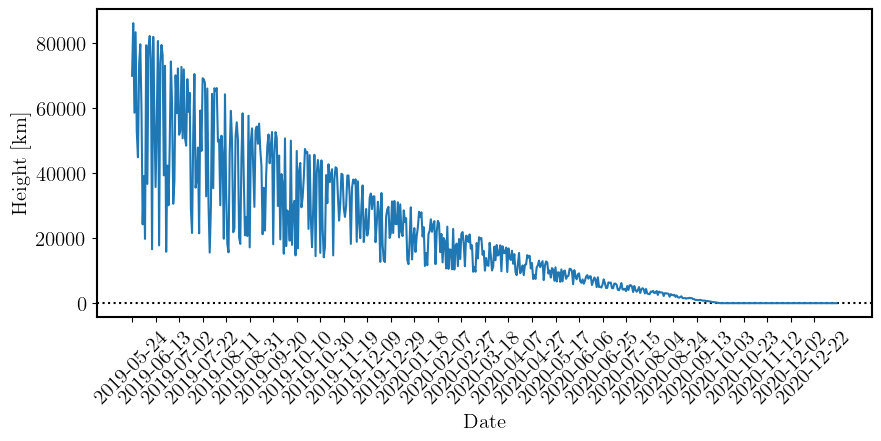

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(10,4))
ax.axhline(0, color='k', ls=':')
ax.plot(np.arange(len(heights)), heights)
step = 20
_ = ax.set_xticks(np.arange(0, len(heights), step=step), labels=dates[::20], rotation=45)
ax.set_ylabel(r'Height [km]')
ax.set_xlabel('Date')
print('Decay date is 2020/10/01')

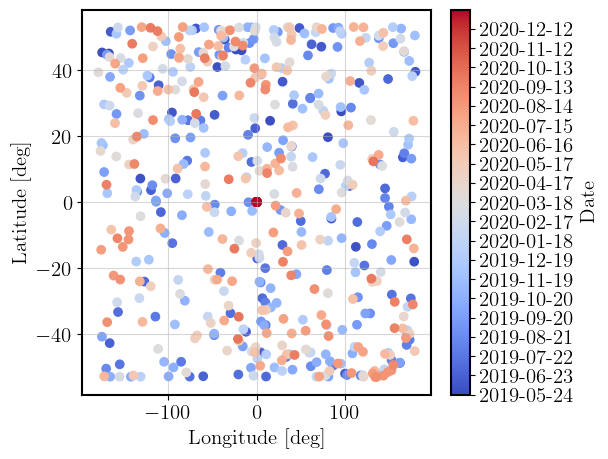

In [16]:
cmap = colormaps['coolwarm']
norm = colors.Normalize(vmin=0, vmax=len(dates)) 

fig, ax = plt.subplots(figsize=(5, 5))
plt.scatter(longitudes, latitudes, color=[cmap(norm(u)) for u in range(len(dates))])
ax.set_xlabel(r'Longitude [deg]')
ax.set_ylabel('Latitude [deg]')
ax.grid(visible=True, alpha=0.5)

sm = plt.cm.ScalarMappable(cmap=cmap,norm=norm)
c_bar=plt.colorbar(sm,fraction=0.05, label='Date', ax=ax)
c_bar.set_ticks(np.arange(0, len(heights), step=30), labels=dates[::30])


Text(0.5, 0.92, 'In geocentric frame')

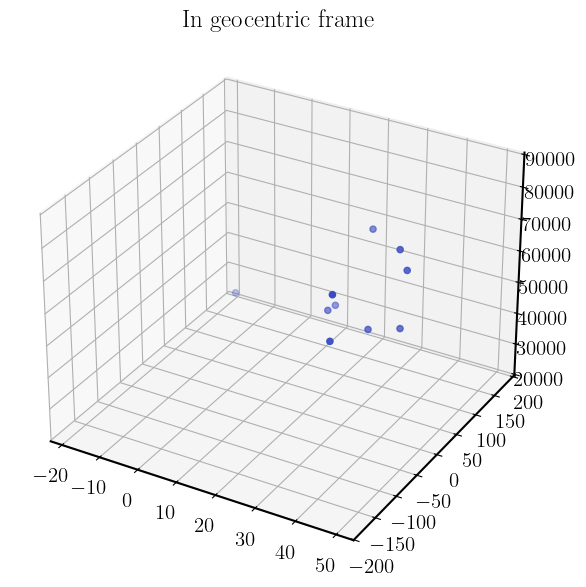

In [17]:
fig = plt.figure(figsize = (10, 7))
ax = plt.axes(projection ="3d")
ax.scatter3D(latitudes[:10], longitudes[:10], heights[:10], color=[cmap(norm(u)) for u in range(len(dates[:10]))])
ax.set_title('In geocentric frame')

HERA coordinates:

In [16]:
hera = pyuvdata.get_telescope('HERA')
telescope_location = hera.location_lat_lon_alt_degrees * units.deg